# Notebook — Single Audio File Analysis

**Purpose:** Descriptive analysis of one audio file in the DCASE 2024
Task~5 validation set. Produces the numbers and figures that support
the *Dataset* and *Results* sections of the paper (event counts, POS
duration statistics, class layout, waveform, and spectrogram views).

**Input:** One `.wav` file and its matching annotation `.csv`
(same base name, produced by the dataset authors).

**Outputs:**
1. File-level summary table (duration, sample rate, number of annotated events)
2. Per-class POS event statistics (count, mean/median/std duration, total POS time)
3. Distribution of POS event durations (histogram + boxplot)
4. Annotation timeline strip (POS events colour-coded by class)
5. Log-mel spectrogram of the full recording, with POS events overlaid
6. Waveform + spectrogram of a single POS event (zoom-in)

## 0 — Configuration

Point `AUDIO_PATH` at any `.wav` file in the Development/Validation set.
The matching `.csv` (same stem) is auto-discovered next to it.

Every figure is written both to the notebook and to `paper/figures/` so it
can be `\includegraphics`'d directly from the LaTeX source.

In [1]:
from pathlib import Path

# ── Which audio file to analyse ────────────────────────────────────────
# Any .wav in the Development_Set. The paired annotation CSV must sit next
# to it with the same stem (e.g. ME1.wav ↔ ME1.csv).
AUDIO_PATH = Path(
    "/media/helios/Data/Uni/Masters/Dataset/Development_Set/Validation_Set/HB/R4_cleaned recording_17-10-17.wav"
)

# Feature-extraction parameters — kept identical to data_preparation.py so
# the spectrogram matches what the model actually sees.
SR      = 22050   # target sample rate (Hz)
N_FFT   = 1024
HOP     = 256
N_MELS  = 128
FMAX    = 11025

# Figures written here so they can be \includegraphics-ed from the paper.
FIG_DIR = Path("../../../paper/figures").resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)

# All figures use a common prefix so multiple runs (different files) don't
# stomp on each other. Override this if you want to name outputs manually.
FIG_PREFIX = AUDIO_PATH.stem  # e.g. "ME1"

assert AUDIO_PATH.exists(), f"Audio file not found: {AUDIO_PATH}"
ANN_PATH = AUDIO_PATH.with_suffix(".csv")
assert ANN_PATH.exists(),   f"Annotation CSV not found: {ANN_PATH}"

print(f"Audio : {AUDIO_PATH}")
print(f"Ann.  : {ANN_PATH}")
print(f"Figs  : {FIG_DIR}")

Audio : /media/helios/Data/Uni/Masters/Dataset/Development_Set/Validation_Set/HB/R4_cleaned recording_17-10-17.wav
Ann.  : /media/helios/Data/Uni/Masters/Dataset/Development_Set/Validation_Set/HB/R4_cleaned recording_17-10-17.csv
Figs  : /media/helios/Masters/Repository/dcase-few-shot-bioacoustic/paper/figures


## 1 — Load Audio and Annotations

- `y` is the mono waveform at `SR = 22050 Hz` (the sample rate used by the
  baseline).
- The annotation CSV has columns `Audiofilename, Starttime, Endtime`
  followed by one column per class. Values are `POS`, `NEG` or `UNK`.

In [2]:
import librosa
import numpy as np
import pandas as pd

y, _ = librosa.load(str(AUDIO_PATH), sr=SR, mono=True)
duration_s = len(y) / SR

df_ann = pd.read_csv(ANN_PATH, header=0, index_col=False)

# Class columns = everything after Audiofilename/Starttime/Endtime.
META_COLS  = ["Audiofilename", "Starttime", "Endtime"]
CLASS_COLS = [c for c in df_ann.columns if c not in META_COLS]

print(f"Waveform : {len(y):>10,d} samples ({duration_s:.2f} s, {SR} Hz)")
print(f"Rows     : {len(df_ann):>10,d}")
print(f"Classes  : {CLASS_COLS}")
df_ann.head()

Waveform : 14,466,647 samples (656.08 s, 22050 Hz)
Rows     :         41
Classes  : ['Q']


,Audiofilename,Starttime,Endtime,Q
0,R4_cleaned recording_17-10-17.wav,17.513206,19.529114,POS
1,R4_cleaned recording_17-10-17.wav,25.041364,31.734811,POS
2,R4_cleaned recording_17-10-17.wav,36.947824,43.783014,POS
3,R4_cleaned recording_17-10-17.wav,50.224472,52.996346,POS
4,R4_cleaned recording_17-10-17.wav,58.713337,76.888013,POS


## 2 — File Summary

One row per aggregate quantity. Copy the numbers straight into the paper's
dataset/results text.

In [3]:
# A row is a POS event if ANY class column reads "POS".
pos_mask = (df_ann[CLASS_COLS] == "POS").any(axis=1)
unk_mask = (df_ann[CLASS_COLS] == "UNK").any(axis=1)

pos_events = df_ann[pos_mask].copy()
pos_events["duration"] = pos_events["Endtime"] - pos_events["Starttime"]

total_pos_time = pos_events["duration"].sum()

summary = pd.DataFrame(
    {
        "Value": [
            AUDIO_PATH.name,
            f"{duration_s:.2f}",
            f"{len(y):,d}",
            f"{SR}",
            len(CLASS_COLS),
            len(df_ann),
            int(pos_mask.sum()),
            int(unk_mask.sum()),
            f"{total_pos_time:.2f}",
            f"{100 * total_pos_time / duration_s:.2f}",
        ]
    },
    index=[
        "Filename",
        "Duration (s)",
        "Samples",
        "Sample rate (Hz)",
        "# Classes",
        "# Annotated rows",
        "# POS events",
        "# UNK events",
        "Total POS time (s)",
        "POS coverage (% of duration)",
    ],
)
summary

,Value
Filename,R4_cleaned recording_17-10-17.wav
Duration (s),656.08
Samples,"14,466,647"
Sample rate (Hz),22050
# Classes,1
# Annotated rows,41
# POS events,41
# UNK events,0
Total POS time (s),518.72
POS coverage (% of duration),79.06


## 3 — Per-Class POS Event Statistics

For each class, how many POS events there are and how long they last on
average. `mean`, `median` and `std` are in seconds.

In [4]:
rows = []
for c in CLASS_COLS:
    events = df_ann[df_ann[c] == "POS"]
    if events.empty:
        continue
    dur = (events["Endtime"] - events["Starttime"]).values
    rows.append(
        dict(
            Class=c,
            Count=len(dur),
            Mean=np.mean(dur),
            Median=np.median(dur),
            Std=np.std(dur),
            Min=dur.min(),
            Max=dur.max(),
            Total=dur.sum(),
        )
    )

per_class = (
    pd.DataFrame(rows).set_index("Class").sort_values("Count", ascending=False)
)
per_class.round(3)

,Count,Mean,Median,Std,Min,Max,Total
Class,,,,,,,
Q,41,12.652,11.513,7.6,1.827,37.468,518.718


## 4 — POS Duration Distribution

Left: histogram of POS event lengths (all classes pooled).
Right: per-class boxplot (log-scaled Y — event lengths span several orders
of magnitude in the bioacoustic setting).

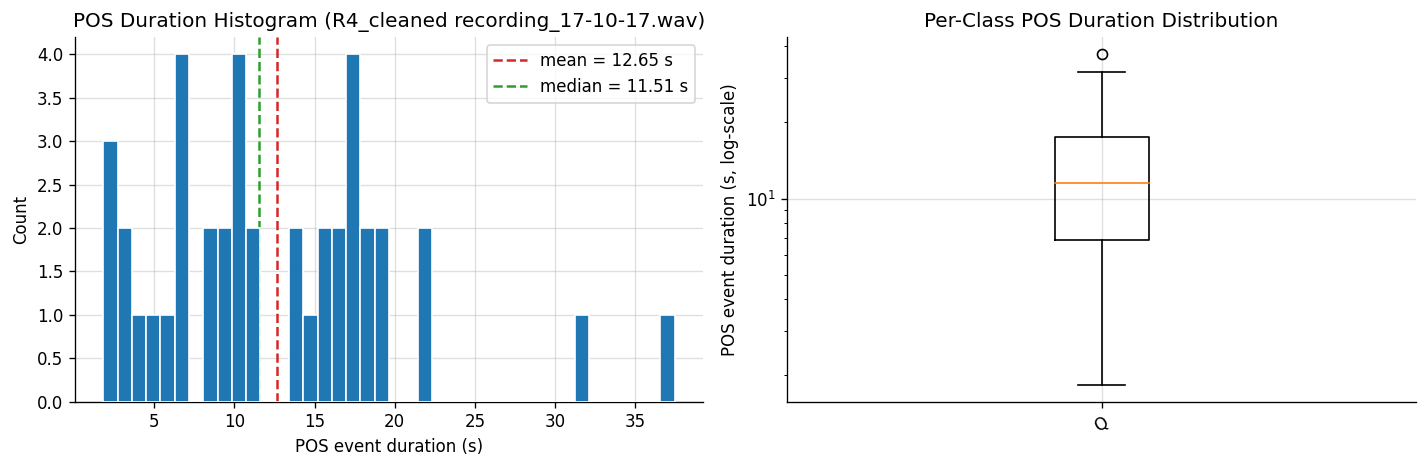

In [5]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "font.size": 10,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ── Histogram (all POS events pooled) ─────────────────────────────────
axes[0].hist(pos_events["duration"].values, bins=40, color="#1f77b4", edgecolor="white", zorder=3)
axes[0].set_xlabel("POS event duration (s)")
axes[0].set_ylabel("Count")
axes[0].set_title(f"POS Duration Histogram ({AUDIO_PATH.name})")
axes[0].axvline(pos_events["duration"].mean(), color="#d62728", linestyle="--", label=f"mean = {pos_events['duration'].mean():.2f} s")
axes[0].axvline(pos_events["duration"].median(), color="#2ca02c", linestyle="--", label=f"median = {pos_events['duration'].median():.2f} s")
axes[0].legend()

# ── Per-class boxplot ─────────────────────────────────────────────────
cls_with_events = [c for c in CLASS_COLS if (df_ann[c] == "POS").any()]
data = [
    (df_ann.loc[df_ann[c] == "POS", "Endtime"] - df_ann.loc[df_ann[c] == "POS", "Starttime"]).values
    for c in cls_with_events
]
axes[1].boxplot(data, labels=cls_with_events, showfliers=True)
axes[1].set_yscale("log")
axes[1].set_ylabel("POS event duration (s, log-scale)")
axes[1].set_title("Per-Class POS Duration Distribution")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(FIG_DIR / f"{FIG_PREFIX}_pos_duration.pdf", bbox_inches="tight")
plt.show()

## 5 — Annotation Timeline

One horizontal strip per class; each coloured bar is a POS event.
Reveals the temporal layout of positive events — dense clusters vs.
long silences vs. one class alternating with another.

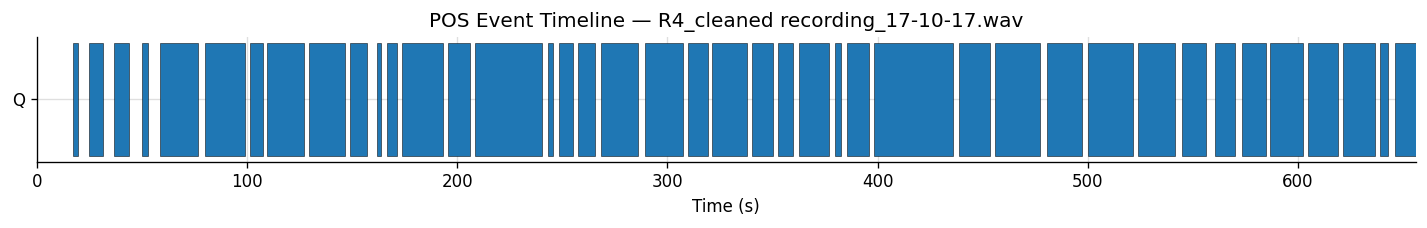

In [6]:
fig, ax = plt.subplots(figsize=(12, max(2.0, 0.4 * len(cls_with_events) + 1.0)))

cmap = plt.get_cmap("tab10")
for i, c in enumerate(cls_with_events):
    events = df_ann[df_ann[c] == "POS"]
    for _, r in events.iterrows():
        ax.barh(
            y=i,
            width=r["Endtime"] - r["Starttime"],
            left=r["Starttime"],
            height=0.6,
            color=cmap(i % 10),
            edgecolor="black",
            linewidth=0.3,
            zorder=3,
        )

ax.set_yticks(range(len(cls_with_events)))
ax.set_yticklabels(cls_with_events)
ax.set_xlabel("Time (s)")
ax.set_xlim(0, duration_s)
ax.set_title(f"POS Event Timeline — {AUDIO_PATH.name}")

plt.tight_layout()
plt.savefig(FIG_DIR / f"{FIG_PREFIX}_timeline.pdf", bbox_inches="tight")
plt.show()

## 6 — Full Waveform and Log-Mel Spectrogram

Top: waveform with POS events shaded in red.
Bottom: log-mel spectrogram (same parameters as the baseline
feature extractor — see `data_preparation.py`).

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:25: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.


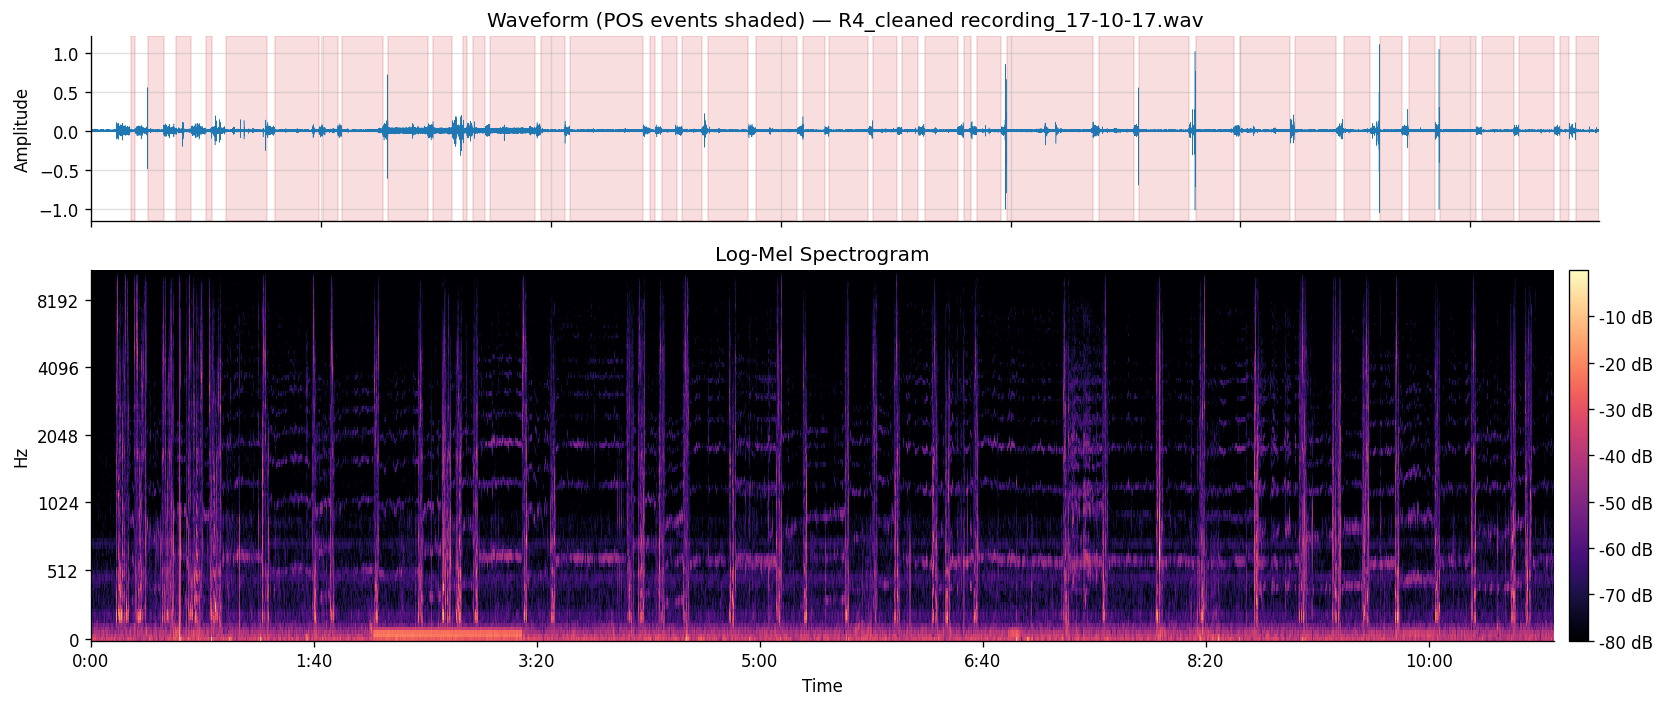

In [7]:
import librosa.display

mel = librosa.feature.melspectrogram(
    y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, fmax=FMAX
)
logmel = librosa.power_to_db(mel, ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2]})

# ── Waveform ──────────────────────────────────────────────────────────
t = np.arange(len(y)) / SR
axes[0].plot(t, y, color="#1f77b4", linewidth=0.3)
for _, r in pos_events.iterrows():
    axes[0].axvspan(r["Starttime"], r["Endtime"], color="#d62728", alpha=0.15, zorder=1)
axes[0].set_ylabel("Amplitude")
axes[0].set_title(f"Waveform (POS events shaded) — {AUDIO_PATH.name}")
axes[0].set_xlim(0, duration_s)

# ── Log-mel spectrogram ───────────────────────────────────────────────
img = librosa.display.specshow(
    logmel, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
    fmax=FMAX, ax=axes[1], cmap="magma"
)
fig.colorbar(img, ax=axes[1], format="%+2.0f dB", fraction=0.02, pad=0.01)
axes[1].set_title("Log-Mel Spectrogram")

plt.tight_layout()
plt.savefig(FIG_DIR / f"{FIG_PREFIX}_waveform_spectrogram.pdf", bbox_inches="tight")
plt.show()

## 7 — Zoom on a Single POS Event

Pick one POS event (default: the median-duration one) and plot its
waveform + spectrogram with a small padding on either side. Handy as an
illustrative figure for the paper's dataset section.

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:48: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.


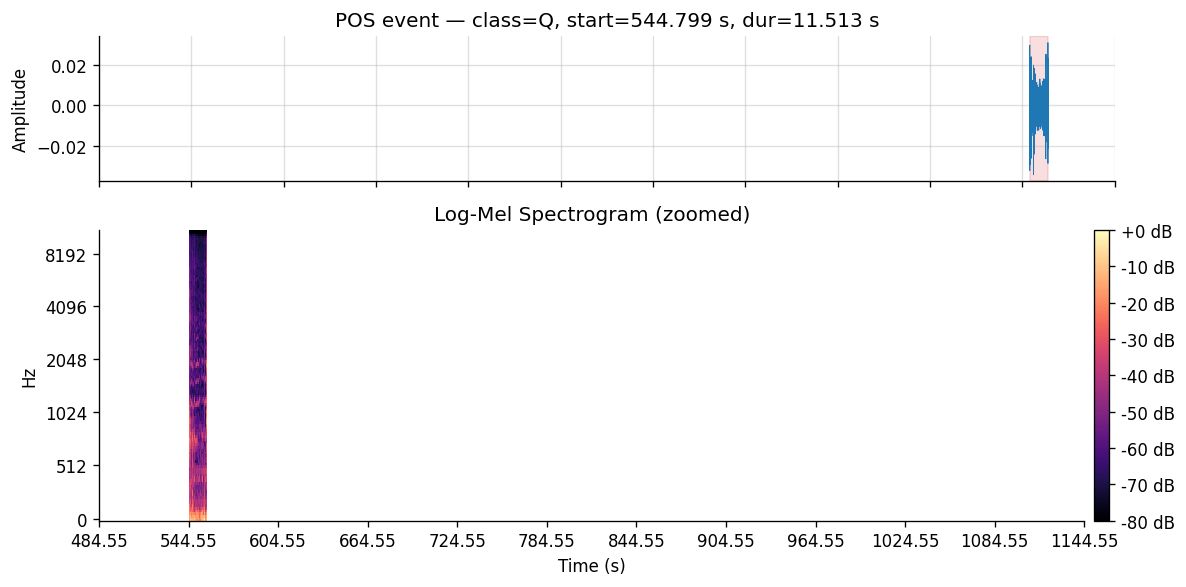

In [8]:
# ── Choose which POS event to show ─────────────────────────────────────
# Default = the event closest to the median duration (representative).
# Set EVENT_INDEX to an integer to force a specific POS event (0-indexed
# into the pos_events DataFrame).
EVENT_INDEX = None
PAD_S       = 0.25   # seconds of context on each side

if EVENT_INDEX is None:
    med = pos_events["duration"].median()
    ev = pos_events.iloc[(pos_events["duration"] - med).abs().argsort().iloc[0]]
else:
    ev = pos_events.iloc[EVENT_INDEX]

start = max(0.0, ev["Starttime"] - PAD_S)
end   = min(duration_s, ev["Endtime"] + PAD_S)

s_smp, e_smp = int(start * SR), int(end * SR)
y_seg = y[s_smp:e_smp]

mel_seg = librosa.feature.melspectrogram(
    y=y_seg, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, fmax=FMAX
)
logmel_seg = librosa.power_to_db(mel_seg, ref=np.max)

# Which class label triggered POS on this row?
row_classes = [c for c in CLASS_COLS if ev[c] == "POS"]
cls_str = ", ".join(row_classes) if row_classes else "(no class column)"

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2]})

t_seg = np.arange(len(y_seg)) / SR + start
axes[0].plot(t_seg, y_seg, color="#1f77b4", linewidth=0.5)
axes[0].axvspan(ev["Starttime"], ev["Endtime"], color="#d62728", alpha=0.15, zorder=1)
axes[0].set_ylabel("Amplitude")
axes[0].set_title(
    f"POS event — class={cls_str}, "
    f"start={ev['Starttime']:.3f} s, dur={ev['Endtime']-ev['Starttime']:.3f} s"
)

img = librosa.display.specshow(
    logmel_seg, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
    fmax=FMAX, ax=axes[1], cmap="magma"
)
# Shift x-ticks so they read absolute file time, not segment-local time.
axes[1].set_xticks(axes[1].get_xticks())
axes[1].set_xticklabels([f"{tick + start:.2f}" for tick in axes[1].get_xticks()])
fig.colorbar(img, ax=axes[1], format="%+2.0f dB", fraction=0.02, pad=0.01)
axes[1].set_xlabel("Time (s)")
axes[1].set_title("Log-Mel Spectrogram (zoomed)")

plt.tight_layout()
plt.savefig(FIG_DIR / f"{FIG_PREFIX}_pos_event.pdf", bbox_inches="tight")
plt.show()

## 8 — Energy Profile

Frame-level RMS energy of the recording, POS regions overlaid. Useful for
checking whether POS events line up with high-energy segments — the
underlying assumption of the Phase 2 (energy-guided) masking strategy.

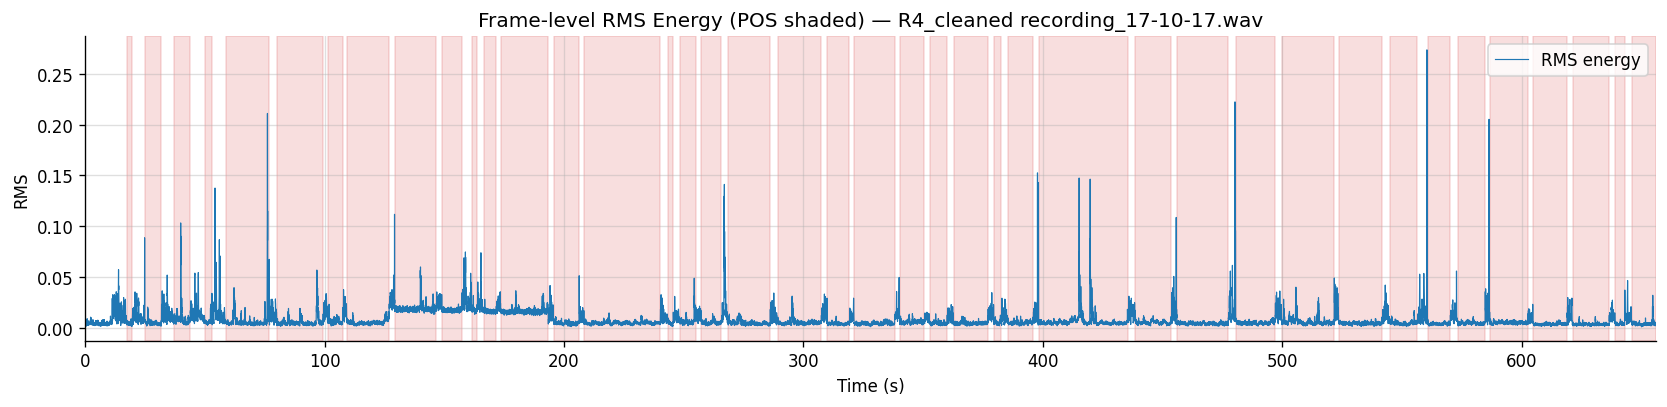

In [9]:
rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP)[0]
t_rms = librosa.frames_to_time(np.arange(len(rms)), sr=SR, hop_length=HOP)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(t_rms, rms, color="#1f77b4", linewidth=0.7, label="RMS energy")
for _, r in pos_events.iterrows():
    ax.axvspan(r["Starttime"], r["Endtime"], color="#d62728", alpha=0.15, zorder=1)
ax.set_xlim(0, duration_s)
ax.set_xlabel("Time (s)")
ax.set_ylabel("RMS")
ax.set_title(f"Frame-level RMS Energy (POS shaded) — {AUDIO_PATH.name}")
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig(FIG_DIR / f"{FIG_PREFIX}_rms.pdf", bbox_inches="tight")
plt.show()